# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:** Fedde Kuiper, Max Kroezen 
**Title of the experiment:** Boltzmann
**Starting date:** 16 nov 2026
**Expected enddate:** -
**Partner:** 
**Goal of the experiment:** Determine the idealality factor `n` of the diode
**Research question:** 
**Expectations or Hypothesis:**  
**Desired accuracy:** 

In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 
import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 400

# Preparation
 


**Assignments:**  
| Resistor Label | Werkelijk (1 kabellengte) | (2 kabellengtes) |
| -------------- | ------------------------- | ---------------- |
| 10 Ω           | 10.155 Ω                  | 17.754 Ω         |
| 100 Ω          | 100.135 Ω                 | 100.200 Ω        |
| 330 Ω 1%       | 329.40 Ω                  |                  |
| 330 Ω 5%       | 325.42 Ω                  |                  |
| 470 Ω          | 468.96 Ω                  |                  |
| 1 kΩ           | 0.99474 kΩ                |                  |
| 4.7 kΩ         | 4.6853 kΩ                 |                  |
| 10 kΩ          | 9.9686 kΩ                 | 9.9687 kΩ        |
| 10 kΩ (2)      | 9.9738 kΩ                 |                  |
| 33 kΩ          | 33.064 kΩ                 |                  |

**Method:** Zie verslag  
**Theory:** Zie verslag  
**Independent variable:** I_d  
**Dependent variable:** V_d  
**Controlled variablen:**  T, R1, R2, R3
**Measurement instruments \& Settings:** Instruments: 2x 5.5 digit multimeter (Siglent SDM3055)  
**Procedure:** We passen U_src aan, vanwege voltage divider is V_R3 ongv. ~ U_src / 4. Iterate tot V_d rond 0.6 aantikt.
**Setup(drawing or picture):**  
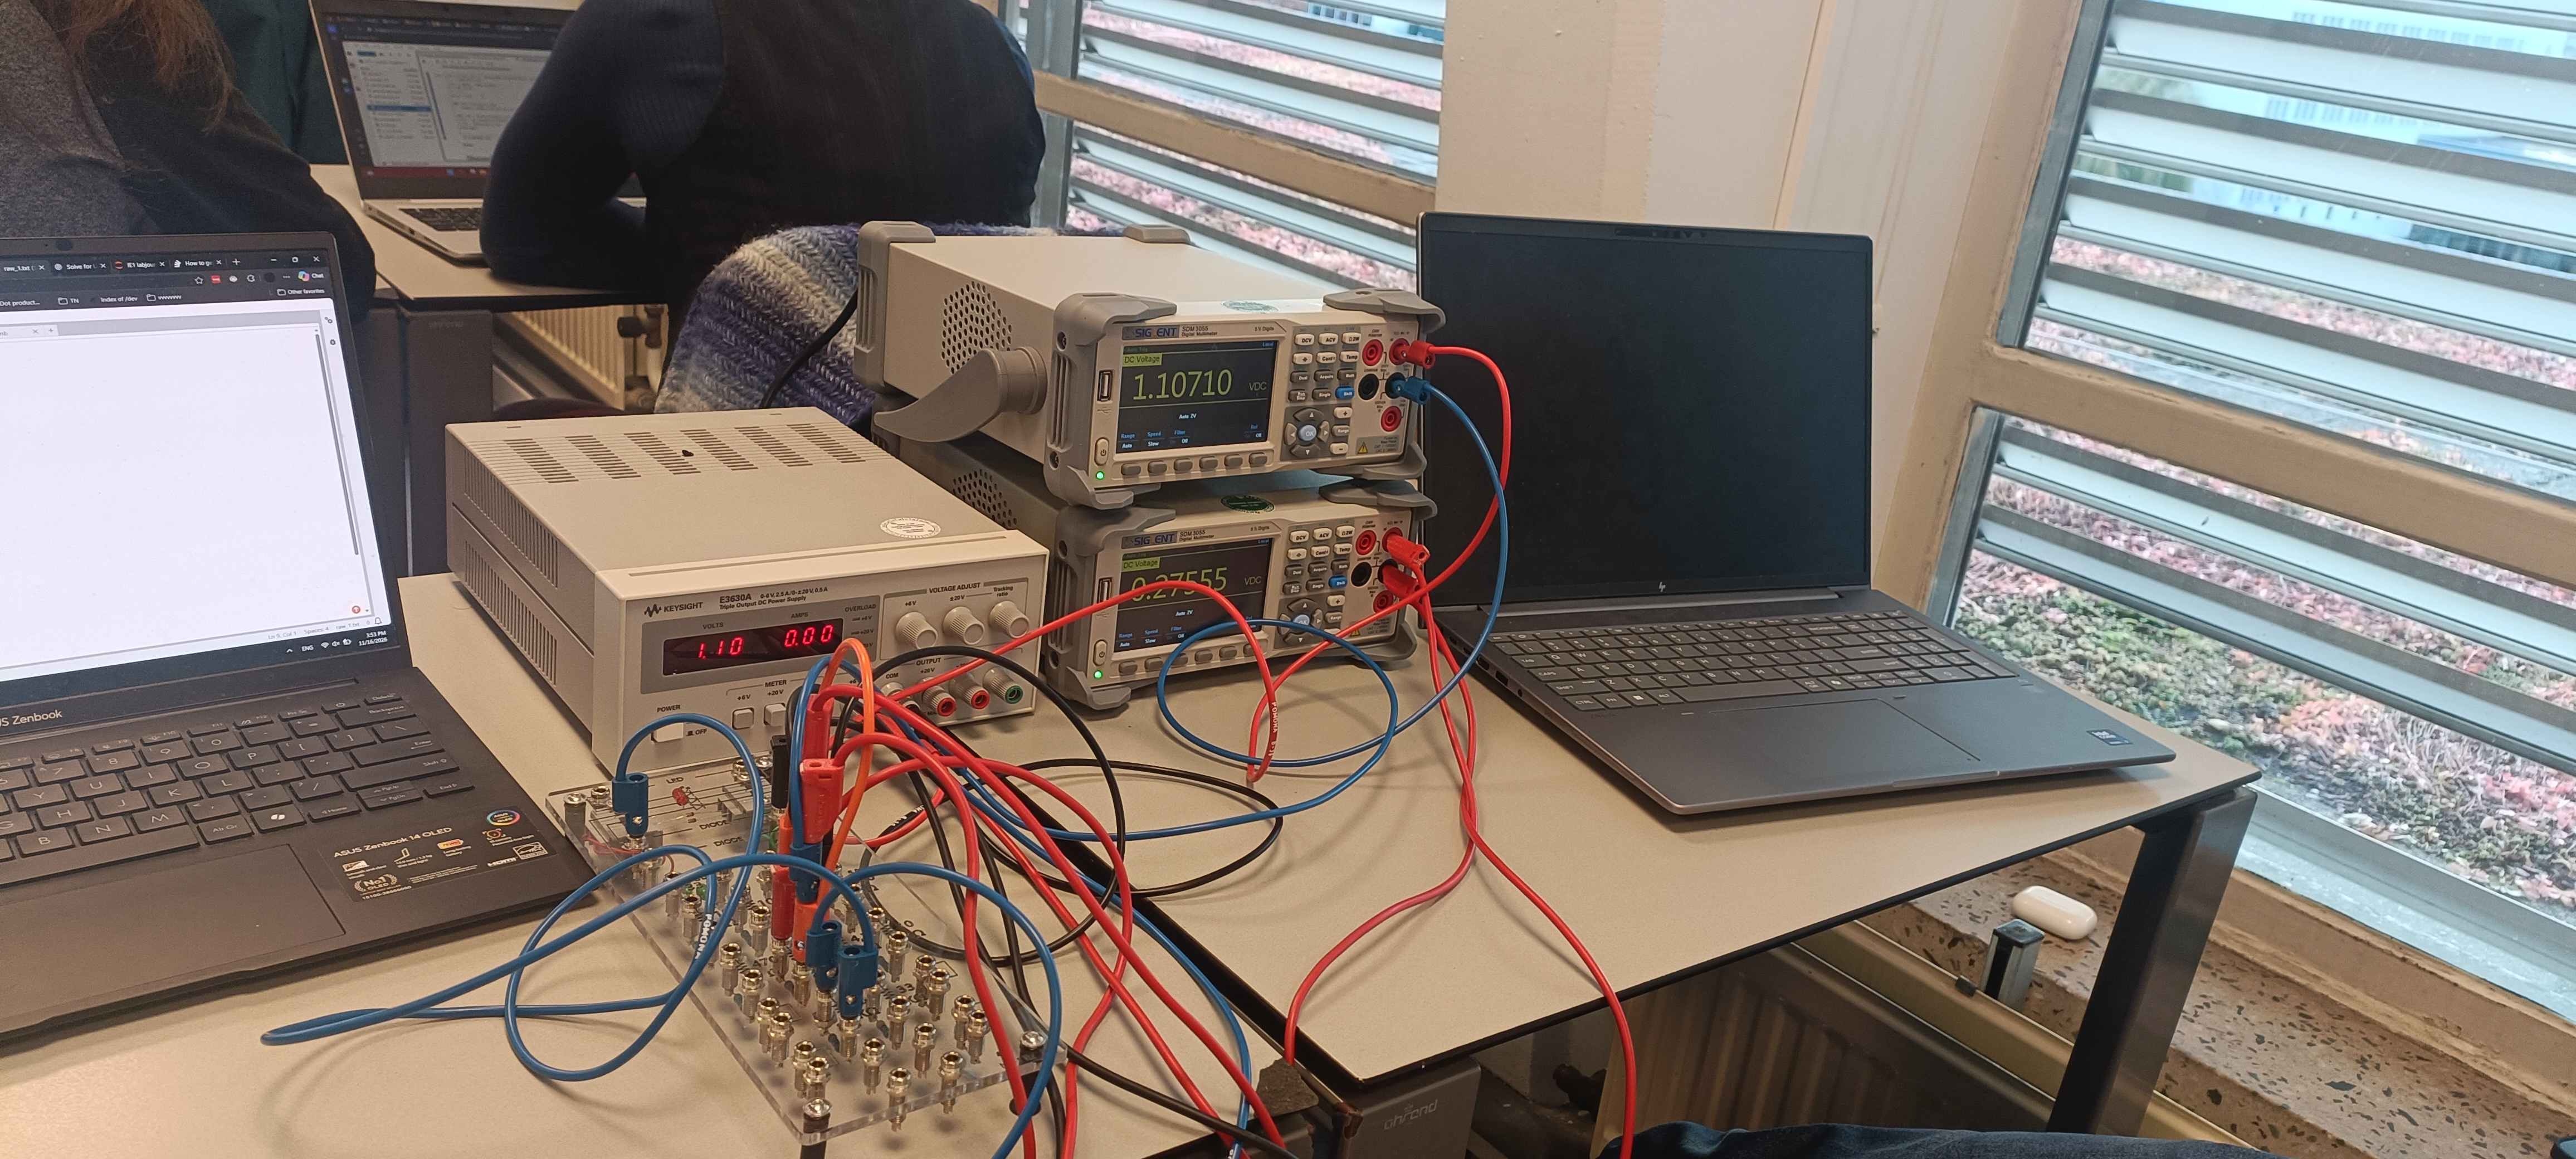
**Notes:** V_d en I_d worden berekend met de gemeten U_src en V_R1  
**About accuracy:** 


In [2]:
q = 1.602176634 * 10 ** -19
n = 2.0 # +/- 0.1 -- idealiteitsfactor van een siciliumdiode

kB_verwacht = 1.380649 * 10 ** -23

T = 20 + 273.15 # kamertemp (K)

R1 = 9.9686 * 1000 
R2 = 0.99474 * 1000
R3 = 329.40 

# de totale weerstand tussen de potentiaalniveaus over R3 (parallel geschakelde weerstand, genomen R_D = 0)
Re = (R3 * R1) / (R3 + R1)

In [3]:
def calc_V_r3(U_src): return U_src * Re/(R2 + Re)
def calc_U_src(V_r3): return V_r3 * (R2 + Re)/Re
def calc_V_d(V_r3, V_r1): return V_r3 - V_r1
def calc_I_d(V_r1): return V_r1 / R1

print("U_src start = ", calc_U_src(0.1))
print("U_src end = ", calc_U_src(0.6))
print("U_src step = ", calc_U_src(0.025))

U_src start =  0.41196416127332
U_src end =  2.4717849676399193
U_src step =  0.10299104031833


# Execution

In [4]:
rd = np.loadtxt("raw_1.txt", dtype=float, delimiter=',', skiprows=1) 
Usrc = rd[:, 0] # U_bron
Vr1 = rd[:, 1] / 1000 # V_R1 (mV -> V)

Vr3 = calc_V_r3(Usrc)
Vd = calc_V_d(Vr3, Vr1)

Id = calc_I_d(Vr1)

# diagnostisch, gebruikt tijdens het meten
if False:
    plt.figure()
    plt.plot(Usrc, Vd, 'k.', label="werkelijk")
    plt.legend()
    plt.show()

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


popt =  [1.20883510e-09 1.19902731e-23]
pcov =  [3.54593974e-20 2.48499658e-50]
mean residual =  -5.194388159607443e-07  relative:  -0.21577203101379558 %


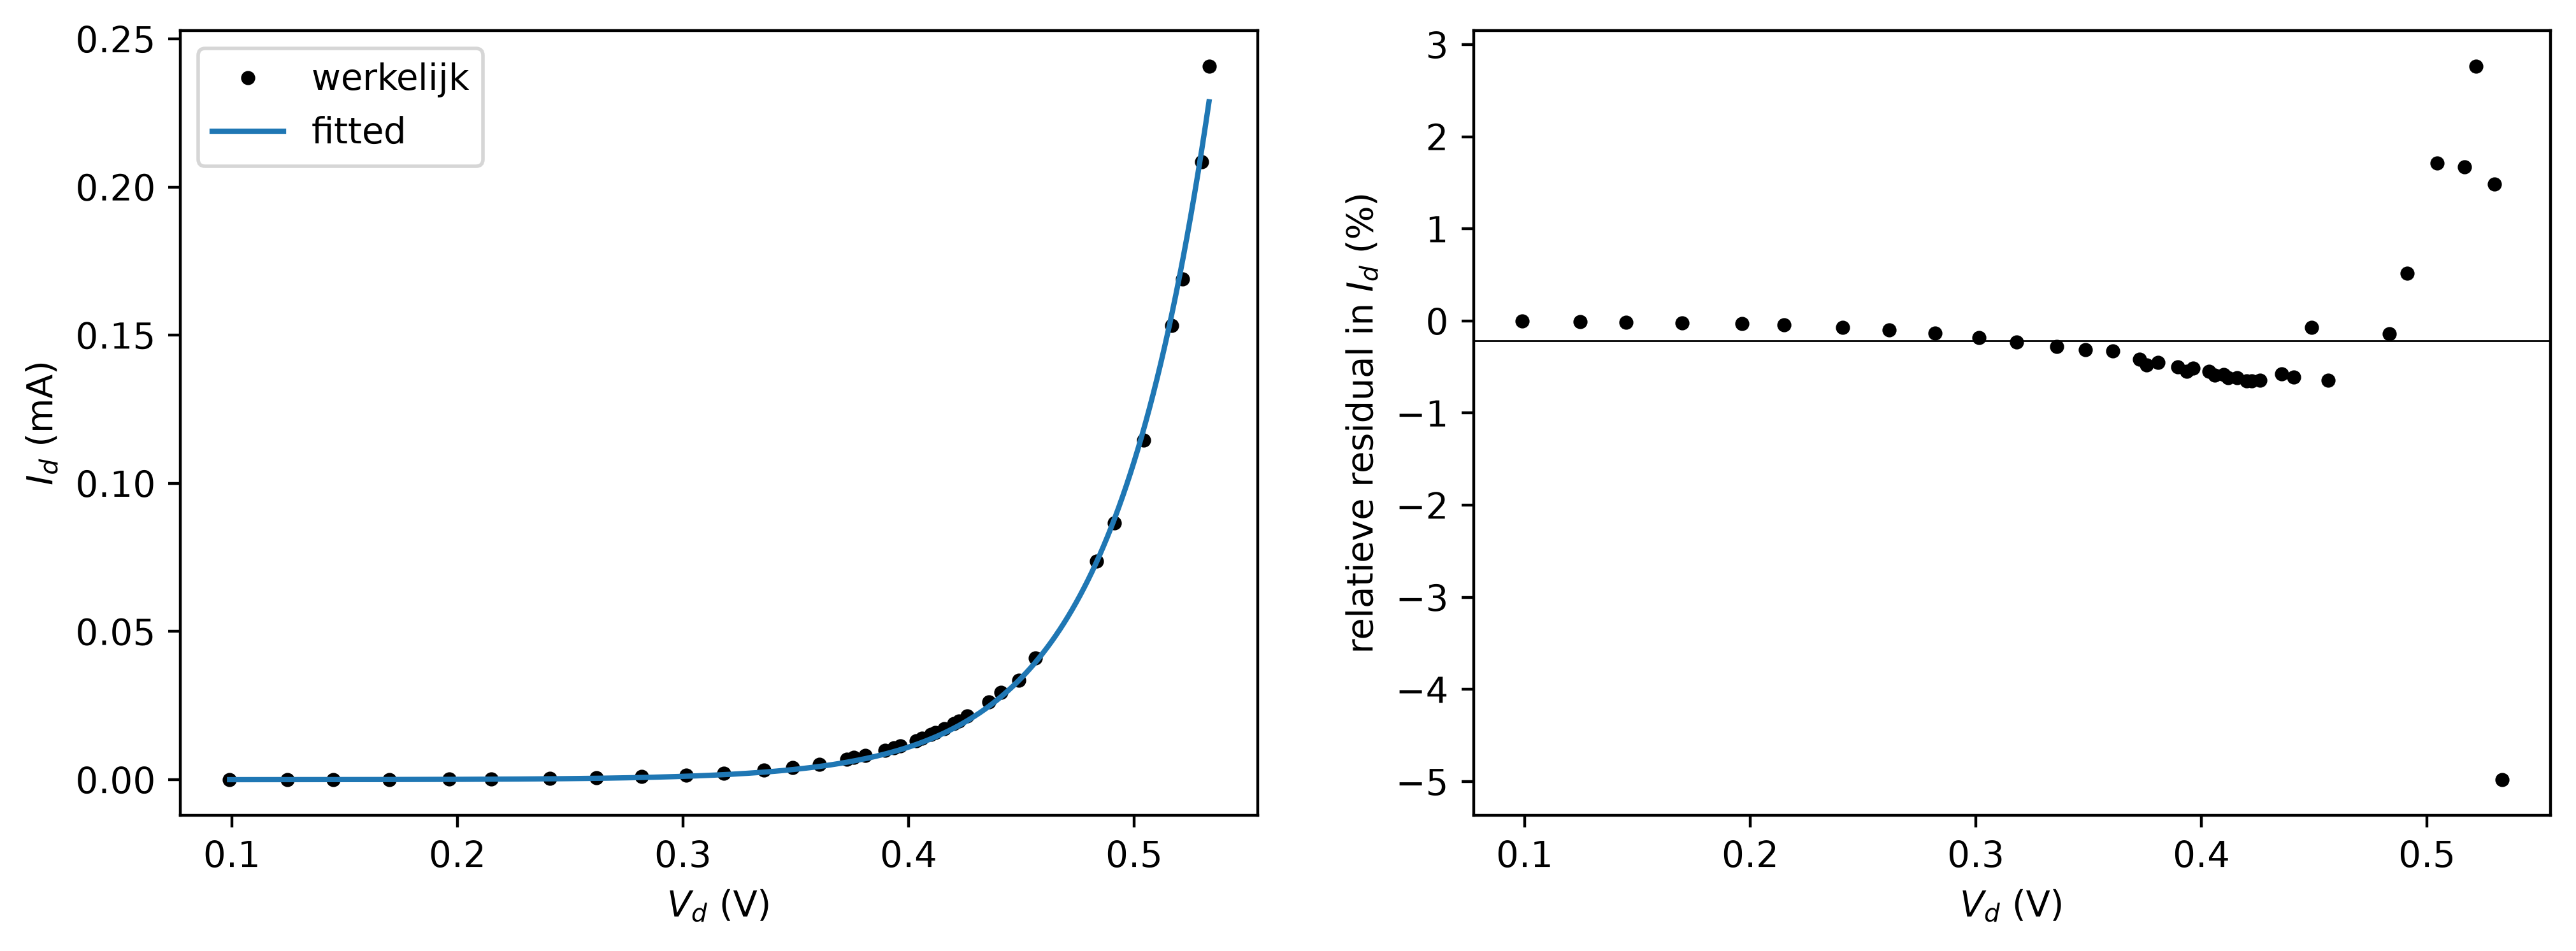

In [16]:
def func(V, I_0, kB):
    return I_0 * (np.exp((q * V)/(n * kB * T)) - 1)

popt, pcov = curve_fit(func, Vd, Id, p0=[0.0000001, kB_verwacht], maxfev=1000000)
print("popt = ", popt)
print("pcov = ", np.diag(pcov))

space = np.linspace(np.min(Vd), np.max(Vd), 10000)
Id_fit = func(space, *popt)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
# plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.plot(Vd, Id * 1000, 'k.', label="werkelijk")
plt.plot(space, Id_fit * 1000, label="fitted")
plt.ylabel("$I_d$ (mA)")
plt.xlabel("$V_d$ (V)")
plt.legend()

height = np.max(Id) - np.min(Id)
residuals = func(Vd, *popt) - Id
residualsRel = residuals / height
meanRes = np.mean(residuals)
meanResRel = meanRes / height
plt.subplot(1, 2, 2)
plt.plot(Vd, residualsRel * 100, 'k.', label="residual")
plt.ylabel("relatieve residual in $I_d$ (%)")
plt.xlabel("$V_d$ (V)")
plt.axhline(meanResRel * 100, color="black", linewidth=0.5)
print("mean residual = ", meanRes, " relative: ", meanResRel * 100, "%")

plt.show()

In [6]:
#Data processing and analysis:


In [7]:
#Data processing and analysis:


**Describing the pattern in the processed data:**  


In [8]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc